# 12 — Joint SIREN skull, brain and internal CT rendering

This notebook trains one patient-specific implicit neural representation:

\[
f(x,y,z)\rightarrow
\left(
\mathrm{HU}_{soft},
\mathrm{HU}_{wide},
\mathrm{SDF}_{brain},
\mathrm{SDF}_{skull}
\right)
\]

The cached TotalSegmentator masks are used as **pseudo-labels** to construct signed-distance targets. The final skull and brain surfaces are evaluated from SIREN outputs and are not direct Marching Cubes conversions of the source masks.

The same network also predicts CT intensity for internal low-attenuation visualization. This is a research visualization, not a diagnostic system.

In [1]:
from __future__ import annotations

import json
import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import torch
import torch.nn as nn
import trimesh
from IPython.display import HTML, display
from scipy import ndimage
from skimage import measure
from skimage.metrics import structural_similarity

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

PROJECT_ROOT = Path(r"F:\csstdy")
SOURCE_DIR = PROJECT_ROOT / "outputs" / "09_totalsegmentator_dl_skull_brain"
CT_PATH = SOURCE_DIR / "input" / "CASE_001_brain_kernel_ct.nii.gz"
BRAIN_MASK_PATH = SOURCE_DIR / "segmentations" / "brain.nii.gz"
SKULL_MASK_PATH = SOURCE_DIR / "segmentations" / "skull.nii.gz"

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "12_siren_neural_skull_brain"
MODEL_DIR = OUTPUT_DIR / "model"
VOLUME_DIR = OUTPUT_DIR / "volumes"
MESH_DIR = OUTPUT_DIR / "meshes"
FIGURE_DIR = OUTPUT_DIR / "figures"
for directory in (OUTPUT_DIR, MODEL_DIR, VOLUME_DIR, MESH_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

CROP_MARGIN = 10
HELD_OUT_EVERY = 9
TRAIN_STEPS = 5000
BATCH_SIZE = 32768
LEARNING_RATE = 2.0e-4
HIDDEN_FEATURES = 160
HIDDEN_LAYERS = 5
SDF_TRUNCATION_MM = 12.0
INFERENCE_CHUNK = 262_144
SOFT_WINDOW = (-100.0, 150.0)
WIDE_WINDOW = (-1000.0, 2000.0)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Output:", OUTPUT_DIR)

Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Output: F:\csstdy\outputs\12_siren_neural_skull_brain


## 1. Native-resolution CT and pseudo-label preparation

Every ninth axial plane is held out from both HU and signed-distance training. This tests whether the neural field can interpolate the patient's intensities and anatomical surfaces into unseen planes.

In [2]:
for required in (CT_PATH, BRAIN_MASK_PATH, SKULL_MASK_PATH):
    if not required.exists():
        raise FileNotFoundError(required)

ct_img = nib.load(CT_PATH)
brain_img = nib.load(BRAIN_MASK_PATH)
skull_img = nib.load(SKULL_MASK_PATH)
ct_full = np.asarray(ct_img.dataobj, dtype=np.float32)
brain_full = np.asarray(brain_img.dataobj) > 0
skull_full = np.asarray(skull_img.dataobj) > 0

if not (ct_full.shape == brain_full.shape == skull_full.shape):
    raise ValueError("CT and masks must have the same shape.")
if not (np.allclose(ct_img.affine, brain_img.affine) and np.allclose(ct_img.affine, skull_img.affine)):
    raise ValueError("CT and masks must have the same affine.")

union = brain_full | skull_full
indices = np.where(union)
lower = np.maximum(np.array([axis.min() for axis in indices]) - CROP_MARGIN, 0).astype(int)
upper = np.minimum(np.array([axis.max() + 1 for axis in indices]) + CROP_MARGIN, ct_full.shape).astype(int)
slices = tuple(slice(int(lo), int(hi)) for lo, hi in zip(lower, upper))

ct = np.ascontiguousarray(ct_full[slices], dtype=np.float32)
brain = np.ascontiguousarray(brain_full[slices])
skull = np.ascontiguousarray(skull_full[slices])
anatomy = brain | skull
head_roi = ndimage.binary_dilation(anatomy, iterations=3)

crop_transform = np.eye(4)
crop_transform[:3, 3] = lower
crop_affine = ct_img.affine @ crop_transform
spacing = np.asarray(ct_img.header.get_zooms()[:3], dtype=np.float32)

held_z = np.arange(5, ct.shape[2] - 5, HELD_OUT_EVERY, dtype=np.int64)
held_planes = np.zeros(ct.shape[2], dtype=bool)
held_planes[held_z] = True
train_plane_mask = np.broadcast_to((~held_planes)[None, None, :], ct.shape)

print("Original shape:", ct_full.shape)
print("Native crop shape:", ct.shape)
print("Spacing (mm):", tuple(spacing))
print("Held-out planes:", held_z.tolist())
print("Brain voxels:", int(brain.sum()), "Skull voxels:", int(skull.sum()))

Original shape: (512, 512, 227)
Native crop shape: (264, 326, 225)
Spacing (mm): (np.float32(0.5557461), np.float32(0.5557461), np.float32(0.75))
Held-out planes: [5, 14, 23, 32, 41, 50, 59, 68, 77, 86, 95, 104, 113, 122, 131, 140, 149, 158, 167, 176, 185, 194, 203, 212]
Brain voxels: 4975324 Skull voxels: 2496034


In [3]:
def hu_to_unit(values: np.ndarray, window: tuple[float, float]) -> np.ndarray:
    lo, hi = window
    return np.clip((values - lo) / (hi - lo), 0.0, 1.0).astype(np.float32)


def unit_to_hu(values: np.ndarray, window: tuple[float, float]) -> np.ndarray:
    lo, hi = window
    return values * (hi - lo) + lo


def signed_distance_target(mask: np.ndarray) -> np.ndarray:
    # Negative inside, positive outside. Values are truncated for stable learning.
    outside = ndimage.distance_transform_edt(~mask, sampling=spacing).astype(np.float32)
    inside = ndimage.distance_transform_edt(mask, sampling=spacing).astype(np.float32)
    sdf_mm = outside - inside
    return np.clip(sdf_mm / SDF_TRUNCATION_MM, -1.0, 1.0).astype(np.float32)


soft_target = hu_to_unit(ct, SOFT_WINDOW)
wide_target = hu_to_unit(ct, WIDE_WINDOW)

sdf_start = time.perf_counter()
brain_sdf_target = signed_distance_target(brain)
skull_sdf_target = signed_distance_target(skull)
print(f"Signed-distance targets built in {time.perf_counter() - sdf_start:.1f} seconds.")

# Compute the isotropic patient-coordinate normalization from the crop corners.
corners = np.array([
    [x, y, z]
    for x in (0, ct.shape[0] - 1)
    for y in (0, ct.shape[1] - 1)
    for z in (0, ct.shape[2] - 1)
], dtype=np.float32)
world_corners = nib.affines.apply_affine(crop_affine, corners).astype(np.float32)
world_center = (world_corners.min(axis=0) + world_corners.max(axis=0)) / 2.0
world_scale = float(np.max(world_corners.max(axis=0) - world_corners.min(axis=0)) / 2.0)

shape_gpu = torch.tensor(ct.shape, dtype=torch.long, device=DEVICE)
affine_gpu = torch.tensor(crop_affine, dtype=torch.float32, device=DEVICE)
center_gpu = torch.tensor(world_center, dtype=torch.float32, device=DEVICE)

soft_gpu = torch.from_numpy(soft_target.reshape(-1)).to(DEVICE)
wide_gpu = torch.from_numpy(wide_target.reshape(-1)).to(DEVICE)
brain_sdf_gpu = torch.from_numpy(brain_sdf_target.reshape(-1)).to(DEVICE)
skull_sdf_gpu = torch.from_numpy(skull_sdf_target.reshape(-1)).to(DEVICE)

def flat_ids(mask: np.ndarray) -> torch.Tensor:
    return torch.from_numpy(np.flatnonzero(mask.reshape(-1))).to(DEVICE)


def ids_to_coordinates(ids: torch.Tensor) -> torch.Tensor:
    yz = shape_gpu[1] * shape_gpu[2]
    ix = torch.div(ids, yz, rounding_mode="floor")
    remainder = ids - ix * yz
    iy = torch.div(remainder, shape_gpu[2], rounding_mode="floor")
    iz = remainder - iy * shape_gpu[2]
    ijk = torch.stack((ix, iy, iz), dim=1).float()
    xyz = ijk @ affine_gpu[:3, :3].T + affine_gpu[:3, 3]
    return (xyz - center_gpu) / world_scale


brain_band = np.abs(brain_sdf_target) < 0.22
skull_band = np.abs(skull_sdf_target) < 0.22
brain_band_pool = flat_ids(brain_band & train_plane_mask)
skull_band_pool = flat_ids(skull_band & train_plane_mask)
brain_inside_pool = flat_ids(brain & train_plane_mask)
skull_inside_pool = flat_ids(skull & train_plane_mask)
context_pool = flat_ids(head_roi & train_plane_mask & ~brain & ~skull)
background_pool = flat_ids((~head_roi) & train_plane_mask)

print("Sampling pools:")
print(" brain boundary:", brain_band_pool.numel())
print(" skull boundary:", skull_band_pool.numel())
print(" brain interior:", brain_inside_pool.numel())
print(" skull interior:", skull_inside_pool.numel())
print(" near-head context:", context_pool.numel())
print(" far background:", background_pool.numel())

Signed-distance targets built in 9.2 seconds.


Sampling pools:
 brain boundary: 1254876
 skull boundary: 2740953
 brain interior: 4422177
 skull interior: 2218862
 near-head context: 749492
 far background: 9908333


## 2. Joint intensity and surface SIREN

The surface channels learn truncated signed distances. The zero level of each predicted distance field defines the neural implicit brain or skull surface.

In [4]:
class SineLayer(nn.Module):
    def __init__(self, in_features: int, out_features: int, *, first: bool = False, omega_0: float = 30.0):
        super().__init__()
        self.in_features = in_features
        self.first = first
        self.omega_0 = omega_0
        self.linear = nn.Linear(in_features, out_features)
        with torch.no_grad():
            bound = 1.0 / in_features if first else math.sqrt(6.0 / in_features) / omega_0
            self.linear.weight.uniform_(-bound, bound)

    def forward(self, values: torch.Tensor) -> torch.Tensor:
        return torch.sin(self.omega_0 * self.linear(values))


class JointSIREN(nn.Module):
    def __init__(self, hidden_features: int, hidden_layers: int):
        super().__init__()
        layers: list[nn.Module] = [SineLayer(3, hidden_features, first=True)]
        layers.extend(SineLayer(hidden_features, hidden_features) for _ in range(hidden_layers))
        self.features = nn.Sequential(*layers)
        self.output = nn.Linear(hidden_features, 4)
        with torch.no_grad():
            bound = math.sqrt(6.0 / hidden_features) / 30.0
            self.output.weight.uniform_(-bound, bound)

    def forward(self, coordinates: torch.Tensor) -> torch.Tensor:
        raw = self.output(self.features(coordinates))
        hu = torch.sigmoid(raw[:, :2])
        sdf = torch.tanh(raw[:, 2:])
        return torch.cat((hu, sdf), dim=1)


model = JointSIREN(HIDDEN_FEATURES, HIDDEN_LAYERS).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=TRAIN_STEPS, eta_min=2.0e-5
)
parameter_count = sum(parameter.numel() for parameter in model.parameters())
print(model)
print(f"Trainable parameters: {parameter_count:,}")

JointSIREN(
  (features): Sequential(
    (0): SineLayer(
      (linear): Linear(in_features=3, out_features=160, bias=True)
    )
    (1): SineLayer(
      (linear): Linear(in_features=160, out_features=160, bias=True)
    )
    (2): SineLayer(
      (linear): Linear(in_features=160, out_features=160, bias=True)
    )
    (3): SineLayer(
      (linear): Linear(in_features=160, out_features=160, bias=True)
    )
    (4): SineLayer(
      (linear): Linear(in_features=160, out_features=160, bias=True)
    )
    (5): SineLayer(
      (linear): Linear(in_features=160, out_features=160, bias=True)
    )
  )
  (output): Linear(in_features=160, out_features=4, bias=True)
)
Trainable parameters: 130,084


In [5]:
def draw(pool: torch.Tensor, count: int) -> torch.Tensor:
    return pool[torch.randint(0, pool.numel(), (count,), device=DEVICE)]


history = []
training_start = time.perf_counter()
model.train()

for step in range(1, TRAIN_STEPS + 1):
    eighth = BATCH_SIZE // 8
    ids = torch.cat((
        draw(brain_band_pool, 2 * eighth),
        draw(skull_band_pool, 2 * eighth),
        draw(brain_inside_pool, eighth),
        draw(skull_inside_pool, eighth),
        draw(context_pool, eighth),
        draw(background_pool, BATCH_SIZE - 7 * eighth),
    ))
    ids = ids[torch.randperm(ids.numel(), device=DEVICE)]
    prediction = model(ids_to_coordinates(ids))

    soft_loss = torch.mean((prediction[:, 0] - soft_gpu[ids]) ** 2)
    wide_loss = torch.mean((prediction[:, 1] - wide_gpu[ids]) ** 2)
    brain_sdf_loss = nn.functional.smooth_l1_loss(prediction[:, 2], brain_sdf_gpu[ids], beta=0.08)
    skull_sdf_loss = nn.functional.smooth_l1_loss(prediction[:, 3], skull_sdf_gpu[ids], beta=0.08)
    loss = 0.22 * soft_loss + 0.13 * wide_loss + 0.30 * brain_sdf_loss + 0.35 * skull_sdf_loss

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    scheduler.step()

    if step == 1 or step % 100 == 0:
        record = {
            "step": step,
            "total": float(loss.detach().cpu()),
            "soft_hu": float(soft_loss.detach().cpu()),
            "wide_hu": float(wide_loss.detach().cpu()),
            "brain_sdf": float(brain_sdf_loss.detach().cpu()),
            "skull_sdf": float(skull_sdf_loss.detach().cpu()),
        }
        history.append(record)
        if step == 1 or step % 500 == 0 or step == TRAIN_STEPS:
            elapsed = time.perf_counter() - training_start
            print(f"step {step:4d}/{TRAIN_STEPS} | loss {record['total']:.6f} | {elapsed:.1f}s")

training_seconds = time.perf_counter() - training_start
print(f"Training completed in {training_seconds:.1f} seconds ({training_seconds / 60:.2f} minutes).")

checkpoint_path = MODEL_DIR / "CASE_001_joint_siren_hu_brain_skull_sdf.pt"
torch.save({
    "model_state_dict": model.state_dict(),
    "architecture": "joint SIREN: soft HU, wide HU, brain SDF, skull SDF",
    "hidden_features": HIDDEN_FEATURES,
    "hidden_layers": HIDDEN_LAYERS,
    "sdf_truncation_mm": SDF_TRUNCATION_MM,
    "soft_window": SOFT_WINDOW,
    "wide_window": WIDE_WINDOW,
    "world_center": world_center,
    "world_scale": world_scale,
    "crop_affine": crop_affine,
    "crop_lower": lower,
}, checkpoint_path)

step    1/5000 | loss 0.290496 | 0.3s


step  500/5000 | loss 0.007213 | 4.9s


step 1000/5000 | loss 0.004862 | 9.5s


step 1500/5000 | loss 0.003988 | 14.2s


step 2000/5000 | loss 0.003606 | 18.8s


step 2500/5000 | loss 0.003470 | 23.5s


step 3000/5000 | loss 0.003130 | 28.2s


step 3500/5000 | loss 0.002985 | 32.9s


step 4000/5000 | loss 0.002884 | 37.6s


step 4500/5000 | loss 0.002754 | 42.3s


step 5000/5000 | loss 0.002735 | 47.0s
Training completed in 47.0 seconds (0.78 minutes).


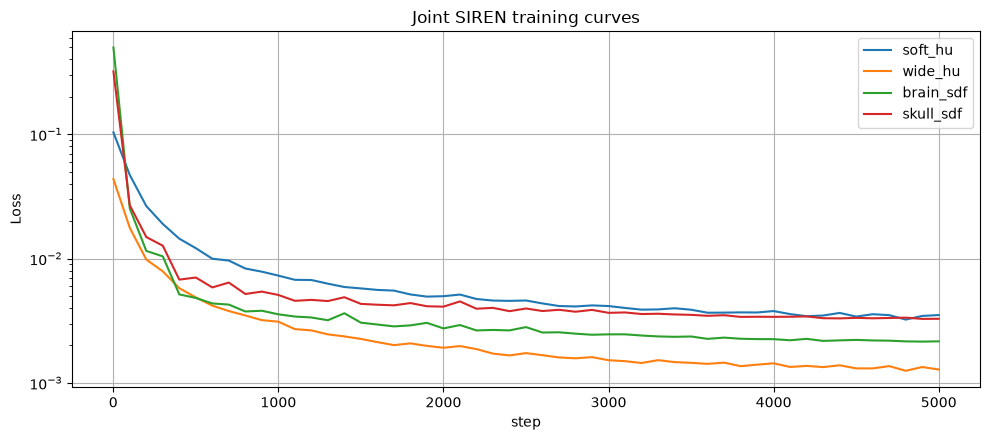

In [6]:
history_df = pd.DataFrame(history)
ax = history_df.plot(
    x="step", y=["soft_hu", "wide_hu", "brain_sdf", "skull_sdf"],
    logy=True, figsize=(10, 4.5), grid=True,
)
ax.set_title("Joint SIREN training curves")
ax.set_ylabel("Loss")
plt.tight_layout()
training_curve_path = FIGURE_DIR / "joint_siren_training_curves.png"
plt.savefig(training_curve_path, dpi=170)
plt.show()

## 3. Native-resolution neural inference and held-out metrics

In [7]:
model.eval()
voxel_count = int(np.prod(ct.shape))
prediction_flat = np.empty((voxel_count, 4), dtype=np.float32)
inference_start = time.perf_counter()

with torch.inference_mode():
    for start in range(0, voxel_count, INFERENCE_CHUNK):
        stop = min(start + INFERENCE_CHUNK, voxel_count)
        ids = torch.arange(start, stop, device=DEVICE)
        prediction_flat[start:stop] = model(ids_to_coordinates(ids)).cpu().numpy()

inference_seconds = time.perf_counter() - inference_start
prediction = prediction_flat.reshape(*ct.shape, 4)
pred_soft_hu = unit_to_hu(prediction[..., 0], SOFT_WINDOW).astype(np.float32)
pred_wide_hu = unit_to_hu(prediction[..., 1], WIDE_WINDOW).astype(np.float32)
pred_brain_sdf = (prediction[..., 2] * SDF_TRUNCATION_MM).astype(np.float32)
pred_skull_sdf = (prediction[..., 3] * SDF_TRUNCATION_MM).astype(np.float32)

raw_pred_brain = pred_brain_sdf <= 0.0
raw_pred_skull = pred_skull_sdf <= 0.0
print(f"Inference completed in {inference_seconds:.2f} seconds for {voxel_count:,} voxels.")

nib.save(nib.Nifti1Image(pred_brain_sdf, crop_affine), VOLUME_DIR / "CASE_001_siren_brain_sdf_mm.nii.gz")
nib.save(nib.Nifti1Image(pred_skull_sdf, crop_affine), VOLUME_DIR / "CASE_001_siren_skull_sdf_mm.nii.gz")
nib.save(nib.Nifti1Image(pred_soft_hu, crop_affine), VOLUME_DIR / "CASE_001_siren_soft_hu.nii.gz")
nib.save(nib.Nifti1Image(pred_wide_hu, crop_affine), VOLUME_DIR / "CASE_001_siren_wide_hu.nii.gz")

Inference completed in 2.24 seconds for 19,364,400 voxels.


In [8]:
held_volume = np.broadcast_to(held_planes[None, None, :], ct.shape)

def overlap_metrics(target: np.ndarray, predicted: np.ndarray, evaluation_mask: np.ndarray) -> dict:
    target_eval = target & evaluation_mask
    predicted_eval = predicted & evaluation_mask
    intersection = int(np.logical_and(target_eval, predicted_eval).sum())
    target_count = int(target_eval.sum())
    predicted_count = int(predicted_eval.sum())
    union = int(np.logical_or(target_eval, predicted_eval).sum())
    return {
        "Dice": 2.0 * intersection / max(target_count + predicted_count, 1),
        "IoU": intersection / max(union, 1),
    }


def held_slice_surface_distances(target: np.ndarray, predicted: np.ndarray) -> tuple[float, float]:
    distances = []
    for z in held_z:
        truth = target[:, :, z]
        estimate = predicted[:, :, z]
        if not truth.any() or not estimate.any():
            continue
        truth_edge = truth ^ ndimage.binary_erosion(truth)
        estimate_edge = estimate ^ ndimage.binary_erosion(estimate)
        truth_distance = ndimage.distance_transform_edt(~truth_edge, sampling=spacing[:2])
        estimate_distance = ndimage.distance_transform_edt(~estimate_edge, sampling=spacing[:2])
        distances.extend(truth_distance[estimate_edge].tolist())
        distances.extend(estimate_distance[truth_edge].tolist())
    distances = np.asarray(distances, dtype=np.float32)
    return float(np.mean(distances)), float(np.percentile(distances, 95))


surface_rows = []
for structure, target, estimate, target_sdf, predicted_sdf in (
    ("Brain", brain, raw_pred_brain, brain_sdf_target * SDF_TRUNCATION_MM, pred_brain_sdf),
    ("Skull", skull, raw_pred_skull, skull_sdf_target * SDF_TRUNCATION_MM, pred_skull_sdf),
):
    row = {"Structure": structure}
    row.update(overlap_metrics(target, estimate, held_volume))
    assd, hd95 = held_slice_surface_distances(target, estimate)
    boundary_band = held_volume & (np.abs(target_sdf) <= 3.0)
    row.update({
        "SDF_MAE_mm_near_surface": float(np.mean(np.abs(predicted_sdf[boundary_band] - target_sdf[boundary_band]))),
        "ASSD_mm": assd,
        "HD95_mm": hd95,
        "Held_out_voxels": int(held_volume.sum()),
    })
    surface_rows.append(row)

surface_metrics_df = pd.DataFrame(surface_rows)
surface_metrics_path = OUTPUT_DIR / "held_out_surface_metrics.csv"
surface_metrics_df.to_csv(surface_metrics_path, index=False)
display(surface_metrics_df.round(4))

,Structure,Dice,IoU,SDF_MAE_mm_near_surface,ASSD_mm,HD95_mm,Held_out_voxels
0,Brain,0.9909,0.9819,0.2467,0.4254,1.1115,2065536
1,Skull,0.9576,0.9187,0.2575,0.4492,1.1115,2065536


In [9]:
def hu_metrics(target: np.ndarray, estimate: np.ndarray, mask: np.ndarray, data_range: float) -> dict:
    error = estimate[mask] - target[mask]
    rmse = float(np.sqrt(np.mean(error ** 2)))
    return {
        "MAE_HU": float(np.mean(np.abs(error))),
        "RMSE_HU": rmse,
        "PSNR_dB": float(20.0 * np.log10(data_range / max(rmse, 1e-8))),
    }


def mean_ssim(target: np.ndarray, estimate: np.ndarray, mask: np.ndarray, window: tuple[float, float]) -> float:
    values = []
    lo, hi = window
    for z in held_z:
        points = np.where(mask[:, :, z])
        if not len(points[0]):
            continue
        x0, x1 = max(int(points[0].min()) - 3, 0), min(int(points[0].max()) + 4, target.shape[0])
        y0, y1 = max(int(points[1].min()) - 3, 0), min(int(points[1].max()) + 4, target.shape[1])
        values.append(structural_similarity(
            np.clip(target[x0:x1, y0:y1, z], lo, hi),
            np.clip(estimate[x0:x1, y0:y1, z], lo, hi),
            data_range=hi - lo,
        ))
    return float(np.mean(values))


hu_rows = []
for region, target, estimate, mask, window in (
    ("Brain window", np.clip(ct, *SOFT_WINDOW), pred_soft_hu, brain & held_volume, SOFT_WINDOW),
    ("Whole-head window", np.clip(ct, *WIDE_WINDOW), pred_wide_hu, head_roi & held_volume, WIDE_WINDOW),
):
    row = {"Region": region}
    row.update(hu_metrics(target, estimate, mask, window[1] - window[0]))
    row["SSIM"] = mean_ssim(target, estimate, mask, window)
    row["Evaluated_voxels"] = int(mask.sum())
    hu_rows.append(row)

hu_metrics_df = pd.DataFrame(hu_rows)
hu_metrics_path = OUTPUT_DIR / "held_out_hu_metrics.csv"
hu_metrics_df.to_csv(hu_metrics_path, index=False)
display(hu_metrics_df.round(4))

,Region,MAE_HU,RMSE_HU,PSNR_dB,SSIM,Evaluated_voxels
0,Brain window,6.3139,8.6735,29.1949,0.7051,553147
1,Whole-head window,54.7975,101.9900,29.3713,0.6954,922148


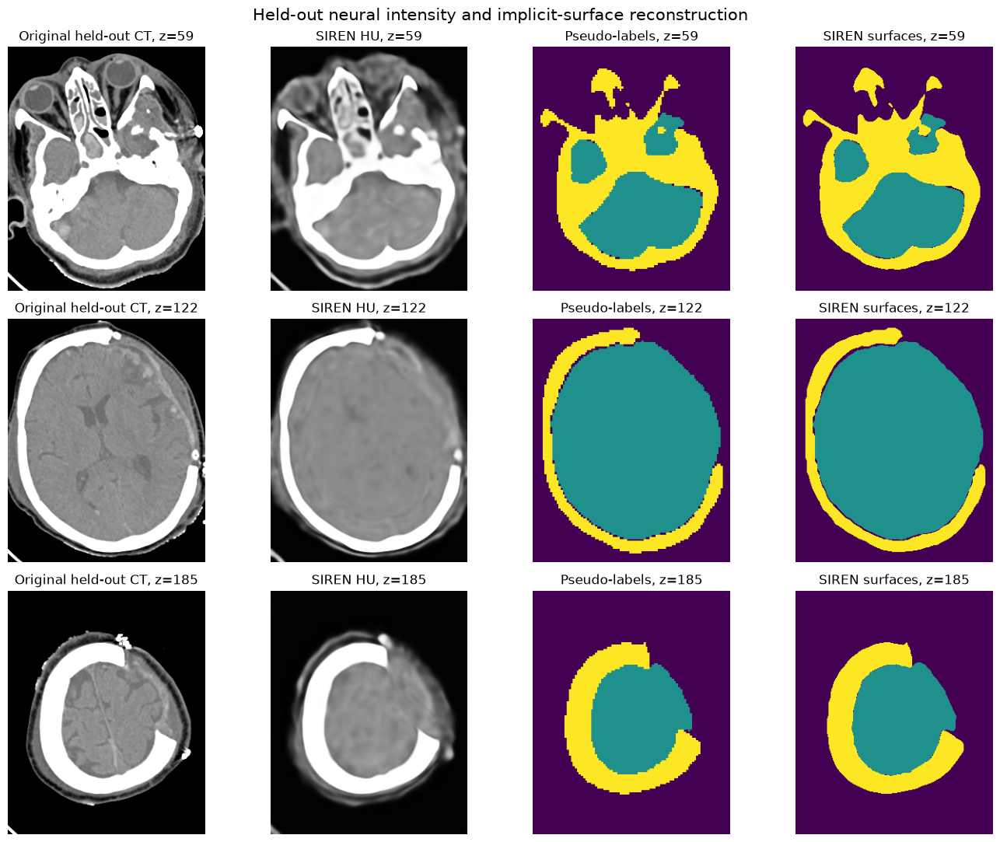

In [10]:
representative = held_z[(brain[:, :, held_z].sum(axis=(0, 1)) > 10000)]
selected_z = representative[np.linspace(0, len(representative) - 1, 3, dtype=int)]
fig, axes = plt.subplots(3, 4, figsize=(14, 11))
for row, z in enumerate(selected_z):
    panels = (
        (np.clip(ct[:, :, z], *SOFT_WINDOW), "Original held-out CT", "gray", SOFT_WINDOW),
        (pred_soft_hu[:, :, z], "SIREN HU", "gray", SOFT_WINDOW),
        (brain[:, :, z] + 2 * skull[:, :, z], "Pseudo-labels", "viridis", (0, 2)),
        (raw_pred_brain[:, :, z] + 2 * raw_pred_skull[:, :, z], "SIREN surfaces", "viridis", (0, 2)),
    )
    for axis, (image, title, cmap, limits) in zip(axes[row], panels):
        axis.imshow(np.rot90(image), cmap=cmap, vmin=limits[0], vmax=limits[1])
        axis.set_title(f"{title}, z={z}")
        axis.axis("off")
plt.suptitle("Held-out neural intensity and implicit-surface reconstruction", fontsize=15)
plt.tight_layout()
comparison_path = FIGURE_DIR / "held_out_siren_comparison.png"
plt.savefig(comparison_path, dpi=170, bbox_inches="tight")
plt.show()

## 4. Extract neural brain, skull and internal-detail geometry

Both anatomical masks below are thresholded from SIREN-predicted signed-distance fields. Connected-component cleanup and light Taubin smoothing remove isolated numerical fragments.

Because coordinate networks can extrapolate unpredictably outside their sampled anatomy, the displayed skull zero-set is limited to a narrow dilation of its pseudo-label support. This is a visualization constraint, not direct meshing of the source mask. Raw held-out metrics above remain unconstrained.

The cyan internal geometry is generated from the SIREN soft-HU field inside the SIREN brain.

In [11]:
def keep_components(mask: np.ndarray, minimum_size: int, maximum_components: int) -> np.ndarray:
    labels, count = ndimage.label(mask)
    if count == 0:
        return mask
    sizes = np.bincount(labels.ravel())
    components = np.flatnonzero(sizes >= minimum_size)
    components = components[components != 0]
    if len(components) > maximum_components:
        components = components[np.argsort(sizes[components])[-maximum_components:]]
    return np.isin(labels, components)


neural_brain = ndimage.binary_closing(raw_pred_brain, iterations=1)
neural_brain = keep_components(neural_brain, minimum_size=5000, maximum_components=1)
neural_brain = ndimage.binary_fill_holes(neural_brain)

# Restrict the displayed SIREN zero-set to a narrow pseudo-label support.
# This removes far-field extrapolation components without directly meshing the source mask.
skull_support = ndimage.binary_dilation(skull, iterations=3)
neural_skull = raw_pred_skull & skull_support
neural_skull = ndimage.binary_closing(neural_skull, iterations=1)
neural_skull = keep_components(neural_skull, minimum_size=250, maximum_components=20)

inner_neural_brain = ndimage.binary_erosion(neural_brain, iterations=4)
internal_low = inner_neural_brain & (pred_soft_hu >= -5.0) & (pred_soft_hu <= 22.0)
internal_low = ndimage.binary_opening(internal_low, iterations=1)
internal_low = keep_components(internal_low, minimum_size=60, maximum_components=20)

print("Neural brain voxels:", int(neural_brain.sum()))
print("Neural skull voxels:", int(neural_skull.sum()))
print("Neural internal low-HU voxels:", int(internal_low.sum()))

nib.save(nib.Nifti1Image(neural_brain.astype(np.uint8), crop_affine), VOLUME_DIR / "CASE_001_siren_brain_mask.nii.gz")
nib.save(nib.Nifti1Image(neural_skull.astype(np.uint8), crop_affine), VOLUME_DIR / "CASE_001_siren_skull_mask.nii.gz")
nib.save(nib.Nifti1Image(internal_low.astype(np.uint8), crop_affine), VOLUME_DIR / "CASE_001_siren_internal_low_hu_mask.nii.gz")

Neural brain voxels: 4961728
Neural skull voxels: 2446609
Neural internal low-HU voxels: 54077


In [ ]:
def create_mesh(mask: np.ndarray, *, step_size: int = 1, smoothing_iterations: int = 3) -> trimesh.Trimesh:
    vertices, faces, _, _ = measure.marching_cubes(
        mask.astype(np.float32), level=0.5, step_size=step_size
    )
    vertices_world = nib.affines.apply_affine(crop_affine, vertices)
    mesh = trimesh.Trimesh(vertices=vertices_world, faces=faces, process=False)
    if smoothing_iterations:
        trimesh.smoothing.filter_taubin(
            mesh, lamb=0.45, nu=0.50, iterations=smoothing_iterations
        )
    return mesh


brain_mesh = create_mesh(neural_brain, step_size=1, smoothing_iterations=4)
skull_mesh = create_mesh(neural_skull, step_size=1, smoothing_iterations=2)
internal_mesh = create_mesh(internal_low, step_size=1, smoothing_iterations=2)

print(f"SIREN brain: {len(brain_mesh.vertices):,} vertices, {len(brain_mesh.faces):,} triangles")
print(f"SIREN skull: {len(skull_mesh.vertices):,} vertices, {len(skull_mesh.faces):,} triangles")
print(f"SIREN internal details: {len(internal_mesh.vertices):,} vertices, {len(internal_mesh.faces):,} triangles")

brain_glb = MESH_DIR / "CASE_001_siren_brain.glb"
skull_glb = MESH_DIR / "CASE_001_siren_skull.glb"
combined_glb = MESH_DIR / "CASE_001_siren_skull_brain_internal.glb"
brain_mesh.export(brain_glb)
skull_mesh.export(skull_glb)

brain_scene_mesh = brain_mesh.copy()
brain_scene_mesh.visual.face_colors = [229, 150, 139, 80]
skull_scene_mesh = skull_mesh.copy()
skull_scene_mesh.visual.face_colors = [216, 201, 155, 100]
internal_scene_mesh = internal_mesh.copy()
internal_scene_mesh.visual.face_colors = [36, 183, 255, 255]
scene = trimesh.Scene({
    "siren_brain": brain_scene_mesh,
    "siren_skull": skull_scene_mesh,
    "siren_internal_low_hu": internal_scene_mesh,
})
_ = scene.export(combined_glb)
print("Saved full-resolution GLB meshes:", MESH_DIR)

In [13]:
# Lightweight smoothed previews keep VS Code/Jupyter responsive.
# The detailed native-resolution GLB meshes were exported in the previous cell.
skull_preview_mesh = create_mesh(neural_skull, step_size=3, smoothing_iterations=7)
brain_preview_mesh = create_mesh(neural_brain, step_size=2, smoothing_iterations=7)
internal_preview_mesh = create_mesh(internal_low, step_size=2, smoothing_iterations=3)
print("Inline preview vertices:")
print(" skull:", len(skull_preview_mesh.vertices))
print(" brain:", len(brain_preview_mesh.vertices))
print(" internal:", len(internal_preview_mesh.vertices))

def mesh_trace(mesh: trimesh.Trimesh, *, name: str, color: str, opacity: float) -> go.Mesh3d:
    vertices = np.asarray(mesh.vertices)
    faces = np.asarray(mesh.faces)
    return go.Mesh3d(
        x=vertices[:, 0], y=vertices[:, 1], z=vertices[:, 2],
        i=faces[:, 0], j=faces[:, 1], k=faces[:, 2],
        name=name, color=color, opacity=opacity,
        flatshading=False,
        lighting=dict(ambient=0.35, diffuse=0.75, specular=0.30, roughness=0.55),
        lightposition=dict(x=100, y=-200, z=100),
        hoverinfo="name",
    )


def finish_figure(figure: go.Figure, title: str, *, show_legend: bool = True) -> go.Figure:
    figure.update_layout(
        title=title,
        template="plotly_dark",
        scene=dict(
            aspectmode="data",
            xaxis_title="Patient X (mm)",
            yaxis_title="Patient Y (mm)",
            zaxis_title="Patient Z (mm)",
            camera=dict(eye=dict(x=1.45, y=-1.65, z=1.15)),
        ),
        showlegend=show_legend,
        legend=dict(x=0.01, y=0.99),
        margin=dict(l=0, r=0, t=55, b=0),
    )
    return figure

Inline preview vertices:
 skull: 57046
 brain: 59126
 internal: 12005


### 4A. SIREN skull, SIREN brain and neural internal details

In [14]:
combined_figure = finish_figure(
    go.Figure([
        mesh_trace(skull_preview_mesh, name="SIREN skull surface", color="#d8c99b", opacity=0.22),
        mesh_trace(brain_preview_mesh, name="SIREN brain surface", color="#e5968b", opacity=0.16),
        mesh_trace(internal_preview_mesh, name="SIREN internal low-HU detail", color="#24b7ff", opacity=0.96),
    ]),
    "Joint SIREN reconstruction — skull, brain and internal CT details",
)
combined_html = OUTPUT_DIR / "CASE_001_siren_skull_brain_internal.html"
combined_figure.write_html(combined_html, include_plotlyjs=True, full_html=True)
print("Interactive model:", combined_html)
display(HTML(f'<a href="{combined_html.as_uri()}" target="_blank">Open skull + brain + internal details in browser</a>'))
display(combined_figure)

Interactive model: F:\csstdy\outputs\12_siren_neural_skull_brain\CASE_001_siren_skull_brain_internal.html


**Static fallback preview — combined**

![Static fallback preview — combined](outputs/12_siren_neural_skull_brain/figures/combined_3d_preview.png)

### 4B. SIREN skull only

In [15]:
skull_figure = finish_figure(
    go.Figure([
        mesh_trace(skull_preview_mesh, name="SIREN skull surface", color="#e0d2a4", opacity=1.0),
    ]),
    "SIREN neural implicit surface — skull only",
    show_legend=False,
)
skull_html = OUTPUT_DIR / "CASE_001_siren_skull_only.html"
skull_figure.write_html(skull_html, include_plotlyjs=True, full_html=True)
print("Interactive model:", skull_html)
display(HTML(f'<a href="{skull_html.as_uri()}" target="_blank">Open SIREN skull in browser</a>'))
display(skull_figure)

Interactive model: F:\csstdy\outputs\12_siren_neural_skull_brain\CASE_001_siren_skull_only.html


**Static fallback preview — skull**

![Static fallback preview — skull](outputs/12_siren_neural_skull_brain/figures/skull_3d_preview.png)

### 4C. SIREN brain and neural internal details

In [16]:
brain_figure = finish_figure(
    go.Figure([
        mesh_trace(brain_preview_mesh, name="SIREN brain surface", color="#e5968b", opacity=0.16),
        mesh_trace(internal_preview_mesh, name="SIREN internal low-HU detail", color="#24b7ff", opacity=0.98),
    ]),
    "SIREN neural implicit brain with internal low-HU details",
)
brain_html = OUTPUT_DIR / "CASE_001_siren_brain_internal.html"
brain_figure.write_html(brain_html, include_plotlyjs=True, full_html=True)
print("Interactive model:", brain_html)
display(HTML(f'<a href="{brain_html.as_uri()}" target="_blank">Open SIREN brain + internal details in browser</a>'))
display(brain_figure)

Interactive model: F:\csstdy\outputs\12_siren_neural_skull_brain\CASE_001_siren_brain_internal.html


**Static fallback preview — brain**

![Static fallback preview — brain](outputs/12_siren_neural_skull_brain/figures/brain_3d_preview.png)

## 5. Neural intensity ray rendering

These projections use only the SIREN-predicted soft-tissue HU field and the SIREN-predicted brain interior.

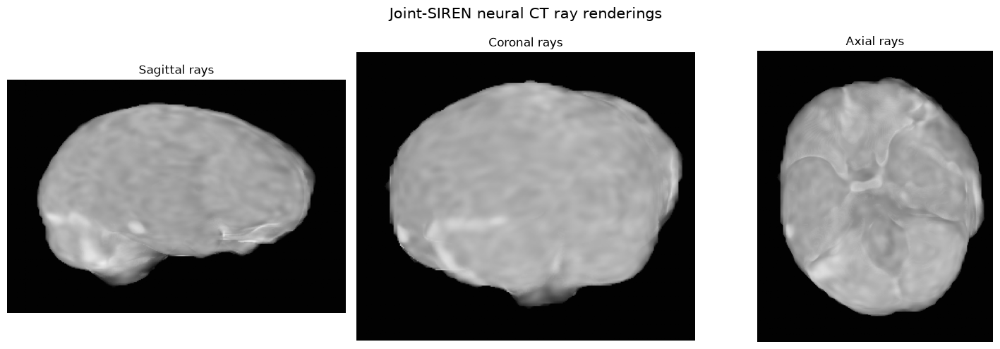

In [17]:
def ray_composite(volume_hu: np.ndarray, region_mask: np.ndarray, axis: int) -> np.ndarray:
    hu = np.moveaxis(volume_hu, axis, -1)
    mask = np.moveaxis(region_mask, axis, -1)
    intensity = np.clip((hu + 20.0) / 90.0, 0.0, 1.0)
    alpha = np.where(mask, 0.020 + 0.045 * intensity, 0.0).astype(np.float32)
    transmittance = np.cumprod(1.0 - alpha + 1e-7, axis=-1)
    before = np.concatenate((np.ones_like(transmittance[..., :1]), transmittance[..., :-1]), axis=-1)
    weights = alpha * before
    rendered = np.sum(weights * (0.08 + 0.92 * intensity), axis=-1)
    return np.clip(rendered + transmittance[..., -1] * 0.01, 0.0, 1.0)


views = {
    "Sagittal rays": ray_composite(pred_soft_hu, neural_brain, axis=0),
    "Coronal rays": ray_composite(pred_soft_hu, neural_brain, axis=1),
    "Axial rays": ray_composite(pred_soft_hu, neural_brain, axis=2),
}
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for axis, (title, image) in zip(axes, views.items()):
    axis.imshow(np.rot90(image), cmap="gray", vmin=0, vmax=1)
    axis.set_title(title)
    axis.axis("off")
plt.suptitle("Joint-SIREN neural CT ray renderings", fontsize=15)
plt.tight_layout()
ray_path = FIGURE_DIR / "joint_siren_ray_renderings.png"
plt.savefig(ray_path, dpi=180, bbox_inches="tight")
plt.show()

## 6. Reproducibility summary

Metrics quantify agreement with the held-out CT intensities and TotalSegmentator-derived pseudo-labels for this single anonymized patient. They do not measure clinical accuracy against manual expert annotation.

In [18]:
summary = {
    "case": "CASE_001",
    "method": "joint patient-specific SIREN neural implicit rendering",
    "network_outputs": ["soft_window_hu", "wide_window_hu", "brain_sdf", "skull_sdf"],
    "pseudo_label_source": "cached TotalSegmentator brain and skull masks",
    "source_ct": str(CT_PATH),
    "native_crop_shape": list(ct.shape),
    "spacing_mm": spacing.tolist(),
    "held_out_z_indices": held_z.tolist(),
    "training_steps": TRAIN_STEPS,
    "trainable_parameters": parameter_count,
    "training_seconds": training_seconds,
    "inference_seconds": inference_seconds,
    "surface_metrics": surface_metrics_df.to_dict(orient="records"),
    "hu_metrics": hu_metrics_df.to_dict(orient="records"),
    "outputs": {
        "checkpoint": str(checkpoint_path),
        "brain_glb": str(brain_glb),
        "skull_glb": str(skull_glb),
        "combined_glb": str(combined_glb),
        "combined_html": str(combined_html),
        "skull_html": str(skull_html),
        "brain_html": str(brain_html),
        "surface_metrics": str(surface_metrics_path),
        "hu_metrics": str(hu_metrics_path),
        "held_out_comparison": str(comparison_path),
        "ray_renderings": str(ray_path),
    },
    "limitation": "Pseudo-label fidelity is not clinical ground-truth accuracy; low-HU detail is visualization-only.",
}
summary_path = OUTPUT_DIR / "joint_siren_summary.json"
summary_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(json.dumps({
    "training_minutes": round(training_seconds / 60.0, 2),
    "inference_seconds": round(inference_seconds, 2),
    "parameters": parameter_count,
    "summary": str(summary_path),
}, indent=2))

{
  "training_minutes": 0.78,
  "inference_seconds": 2.24,
  "parameters": 130084,
  "summary": "F:\\csstdy\\outputs\\12_siren_neural_skull_brain\\joint_siren_summary.json"
}
